# Iris Flower Classification Project

This notebook demonstrates an end-to-end Machine Learning workflow on the classic **Iris dataset** from `scikit-learn`.

### Assignment Overview
1. **Environment Setup & Verification**: Confirming the virtual environment (`.venv`) and all required data science libraries.
2. **Data Loading**: Loading the Iris dataset from `sklearn.datasets` into a Pandas DataFrame.
3. **Exploratory Data Analysis (EDA)**: Inspecting the first few rows, dataset dimensions, class distribution, and descriptive statistics.
4. **Data Visualization**: Creating a pairplot and a feature correlation heatmap.
5. **Data Splitting**: Splitting the dataset into 80% training and 20% testing sets using stratified sampling.
6. **Model Training**: Training two distinct classifiers — **Logistic Regression** and **Random Forest**.
7. **Model Evaluation**: Comparing both models using accuracy, precision/recall/F1-score classification reports, and confusion matrices.
8. **Model Export**: Selecting the best-performing model and saving it as `iris_model.pkl` with `joblib` for deployment.

## Section 1: Environment Setup & Library Verification

### Plain English Explanation:
Before training machine learning models, we set up an isolated workspace called a **virtual environment** (`.venv`). This ensures all dependencies have compatible versions and do not interfere with system software.

In this section, we import the core data science libraries:
- **`pandas`**: Used to structure and manipulate tabular data in DataFrames (similar to spreadsheets in Python).
- **`numpy`**: Provides fast mathematical operations and multi-dimensional array support.
- **`matplotlib` & `seaborn`**: Plotting libraries used to visualize distributions and relationships between features.
- **`scikit-learn`**: The premier Python machine learning library containing algorithms, dataset utilities, and evaluation metrics.
- **`joblib`**: A tool to serialize (save) our trained Python models to disk so they can be loaded by other applications (like web apps).

In [1]:
# Import standard and third-party libraries
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Scikit-learn utilities
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Configure notebook plot styles
sns.set_theme(style="whitegrid", font_scale=1.1)
%matplotlib inline

print(f"Python Version:       {sys.version.split()[0]}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"Pandas Version:       {pd.__version__}")
print(f"NumPy Version:        {np.__version__}")
print(f"Joblib Version:       {joblib.__version__}")
print("\nAll libraries imported and verified successfully!")

Matplotlib is building the font cache; this may take a moment.


Python Version:       3.12.7
Scikit-Learn Version: 1.9.1
Pandas Version:       3.1.1
NumPy Version:        2.5.5
Joblib Version:       1.6.0

All libraries imported and verified successfully!


## Section 2: Loading the Iris Dataset

### Plain English Explanation:
The Iris dataset is a famous dataset in statistics and machine learning introduced by British statistician Ronald Fisher in 1936.

It consists of **150 observations** of iris flowers across **3 species**:
1. *Iris-setosa*
2. *Iris-versicolor*
3. *Iris-virginica*

For every flower, 4 physical measurements (in centimeters) were recorded:
- **Sepal length** (cm)
- **Sepal width** (cm)
- **Petal length** (cm)
- **Petal width** (cm)

Here, we load this data directly from `sklearn.datasets.load_iris()` and format it into a readable Pandas DataFrame.

In [2]:
# Load raw Iris dataset from scikit-learn
iris = load_iris()

# Convert to DataFrame with feature names as column headers
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Add target integer codes (0, 1, 2) and string species names
df['target'] = iris.target
df['species'] = df['target'].map(lambda idx: iris.target_names[idx])

print(f"Target species names: {list(iris.target_names)}")
print(f"Features:             {list(iris.feature_names)}")

Target species names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Features:             ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## Section 3: Exploratory Data Analysis (EDA) - Structure and Summary Statistics

### Plain English Explanation:
Before jumping into model building, an essential step in data science is **Exploratory Data Analysis (EDA)**. We inspect:
1. **`df.head()`**: The first 5 rows to verify columns, data types, and realistic values.
2. **`df.shape`**: The total dimensions (150 rows by 6 columns).
3. **`df['species'].value_counts()`**: The count of samples for each species. An equal distribution (50 each) means our dataset is **perfectly balanced**, which avoids majority-class bias.
4. **`df.describe()`**: Key summary statistics including the **mean** (average), **standard deviation** (spread), **min/max**, and **quartiles** (25%, 50%/median, 75%) for all 4 flower measurements.

In [3]:
# 1. Display first 5 rows
print("=== First 5 Rows of the Dataset ===")
display(df.head())

# 2. Dataset Shape
print(f"\n=== Dataset Shape: {df.shape[0]} samples (rows) and {df.shape[1]} columns ===")

# 3. Class Counts
print("\n=== Class Distribution (Sample Count per Species) ===")
print(df['species'].value_counts())

# 4. Summary Statistics for numerical features
print("\n=== Summary Statistics (Features in cm) ===")
display(df[iris.feature_names].describe().round(2))

=== First 5 Rows of the Dataset ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



=== Dataset Shape: 150 samples (rows) and 6 columns ===

=== Class Distribution (Sample Count per Species) ===
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

=== Summary Statistics (Features in cm) ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## Section 4: Data Visualizations (Pairplot & Correlation Heatmap)

### Plain English Explanation:
Visualizations help us uncover relationships and class separability that raw tables of numbers cannot easily show:
1. **Pairplot**: A matrix of scatter plots showing each pair of features against each other, colored by species. On the diagonal, kernel density estimates (KDE) show each feature's individual distribution. Notice that **Setosa** separates cleanly from the other two species with almost any pair involving petal length or petal width!
2. **Correlation Heatmap**: Visualizes the Pearson correlation coefficient between all pairs of numeric features. Coefficients range from `-1` to `+1`:
   - Petal length and petal width have a very strong positive correlation (~0.96), meaning flowers with longer petals almost always have wider petals.
   - Sepal width has a slight negative correlation with petal length and width.

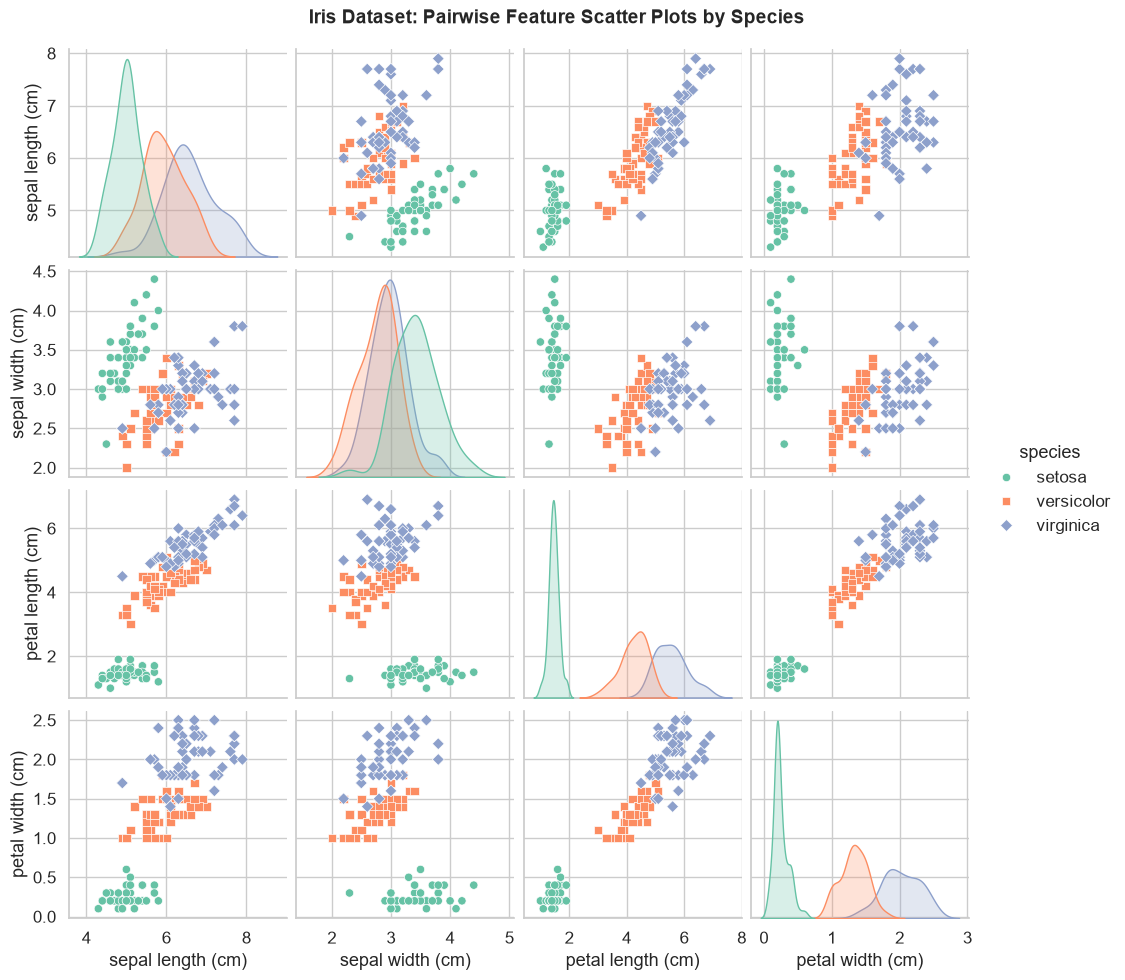

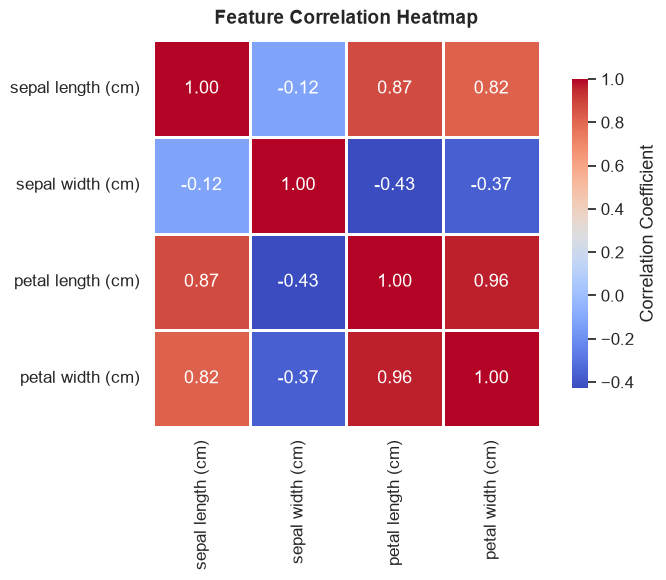

In [4]:
# 1. Pairplot: Pairwise relationships between features grouped by species
pairplot_fig = sns.pairplot(
    df.drop(columns=['target']),
    hue="species",
    palette="Set2",
    diag_kind="kde",
    markers=["o", "s", "D"]
)
pairplot_fig.fig.subplots_adjust(top=0.94)
pairplot_fig.fig.suptitle("Iris Dataset: Pairwise Feature Scatter Plots by Species", fontsize=14, weight="bold")
plt.show()

# 2. Correlation Heatmap: Linear correlation between the 4 numeric measurements
plt.figure(figsize=(8, 6))
corr = df[iris.feature_names].corr()
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8, "label": "Correlation Coefficient"}
)
plt.title("Feature Correlation Heatmap", fontsize=14, weight="bold", pad=12)
plt.tight_layout()
plt.show()

## Section 5: Splitting the Data (80% Train, 20% Test with Stratification)

### Plain English Explanation:
To accurately assess how well a model will perform on future, unseen data, we must never test it on the exact same data it was trained on.

- **80% Training Set (120 samples)**: Used by the machine learning algorithm to learn patterns and decision rules.
- **20% Test Set (30 samples)**: Held out completely during training to act as a fair final exam.
- **Stratification (`stratify=y`)**: This ensures that both train and test splits contain an identical ratio of each class (10 samples of Setosa, 10 of Versicolor, and 10 of Virginica in the test set). This prevents any single class from being accidentally over-represented or omitted.

In [5]:
# Separate input features (X) and target species label (y)
X = df[iris.feature_names]
y = df['target']

# Perform stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Total samples:    {len(X)}")
print(f"Training samples: {len(X_train)} (80%)")
print(f"Testing samples:  {len(X_test)} (20%)")

# Verify balanced distribution in test set
test_counts = pd.Series(y_test).value_counts().rename(index=lambda i: iris.target_names[i])
print("\nTest set class distribution:")
print(test_counts)

Total samples:    150
Training samples: 120 (80%)
Testing samples:  30 (20%)

Test set class distribution:
target
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## Section 6: Training the Classification Models

### Plain English Explanation:
We train two distinct, popular classification algorithms to see which performs best:

1. **Logistic Regression**:
   - Despite its name, Logistic Regression is a powerful classification algorithm.
   - It works by calculating a linear combination of input features and passing it through a softmax function to output class probabilities.
   - It is fast, interpretable, and establishes a great baseline.

2. **Random Forest Classifier**:
   - An **ensemble** method based on decision trees.
   - It creates multiple decision trees (here, 100 trees) on randomly sampled subsets of data and features.
   - When making a prediction, each tree votes, and the majority vote wins. This reduces overfitting and typically yields higher robustness on non-linear boundaries.

In [6]:
# 1. Initialize and train Logistic Regression
log_reg = LogisticRegression(max_iter=200, random_state=42)
log_reg.fit(X_train, y_train)
print("✓ Logistic Regression training complete.")

# 2. Initialize and train Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)
print("✓ Random Forest Classifier training complete.")

✓ Logistic Regression training complete.


✓ Random Forest Classifier training complete.


## Section 7: Evaluating Both Models

### Plain English Explanation:
We now test both trained models on the held-out test data (`X_test`) and evaluate their performance using three standard metrics:

1. **Accuracy**: The percentage of test samples classified correctly.
2. **Classification Report**:
   - **Precision**: How many of the flowers predicted as a certain species actually belonged to that species?
   - **Recall**: Out of all the actual flowers of that species, how many did the model correctly identify?
   - **F1-Score**: The harmonic mean of precision and recall, balancing false positives and false negatives.
3. **Confusion Matrix**: A grid comparing true classes against predicted classes. The diagonal numbers show correct predictions, while off-diagonal cells represent mistakes.

Logistic Regression Test Accuracy: 96.67%
Random Forest Test Accuracy:       90.00%

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


--- Random Forest Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



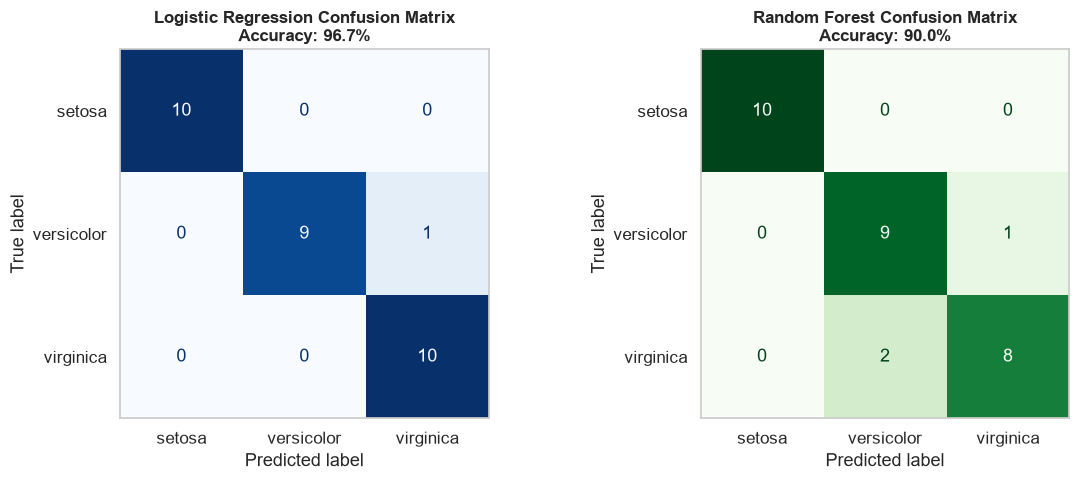

In [7]:
# Generate test set predictions
y_pred_lr = log_reg.predict(X_test)
y_pred_rf = rf_clf.predict(X_test)

# Calculate accuracy scores
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_rf = accuracy_score(y_test, y_pred_rf)

print("=" * 50)
print(f"Logistic Regression Test Accuracy: {acc_lr * 100:.2f}%")
print(f"Random Forest Test Accuracy:       {acc_rf * 100:.2f}%")
print("=" * 50)

# Classification Reports
print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr, target_names=iris.target_names))

print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=iris.target_names))

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=iris.target_names)
disp_lr.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Logistic Regression Confusion Matrix\nAccuracy: {acc_lr*100:.1f}%", fontsize=12, weight="bold")
axes[0].grid(False)

# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=iris.target_names)
disp_rf.plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title(f"Random Forest Confusion Matrix\nAccuracy: {acc_rf*100:.1f}%", fontsize=12, weight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()

## Section 8: Model Selection and Exporting with Joblib

### Plain English Explanation:
In this final step:
1. We automatically select the best model based on test accuracy. If both models achieve identical top accuracy, we choose **Random Forest** for its flexibility and ensemble robustness.
2. We serialize the model and save it as **`iris_model.pkl`** using `joblib.dump()`. This standalone file contains all the learned parameters of the model.
3. We reload the file from disk and run an inference sanity check with sample flower measurements to verify that the saved file is complete, uncorrupted, and ready for deployment in a web application.

In [8]:
# Determine the best model
if acc_rf >= acc_lr:
    best_model = rf_clf
    best_model_name = "Random Forest"
    best_acc = acc_rf
else:
    best_model = log_reg
    best_model_name = "Logistic Regression"
    best_acc = acc_lr

print(f"Selected Best Model: {best_model_name} (Accuracy: {best_acc * 100:.2f}%)")

# Save the model to disk
model_path = "iris_model.pkl"
joblib.dump(best_model, model_path)
file_size = os.path.getsize(model_path)
print(f"✓ Best model serialized and saved successfully to '{model_path}' ({file_size:,} bytes)")

# Verification test: reload model and predict on an example input
loaded_model = joblib.load(model_path)
sample_input = np.array([[5.1, 3.5, 1.4, 0.2]])  # Typical Iris-setosa measurements
pred_label_idx = loaded_model.predict(sample_input)[0]
pred_species_name = iris.target_names[pred_label_idx]

# Check prediction probabilities
if hasattr(loaded_model, 'predict_proba'):
    pred_proba = loaded_model.predict_proba(sample_input)[0]
    confidence = pred_proba[pred_label_idx] * 100
    print(f"Verification Test: Sample {sample_input[0]} -> Predicted: {pred_species_name} (Confidence: {confidence:.1f}%)")
else:
    print(f"Verification Test: Sample {sample_input[0]} -> Predicted: {pred_species_name}")

print("\nReady for Step 2: Flask Web Application!")

Selected Best Model: Logistic Regression (Accuracy: 96.67%)
✓ Best model serialized and saved successfully to 'iris_model.pkl' (1,311 bytes)
Verification Test: Sample [5.1 3.5 1.4 0.2] -> Predicted: setosa (Confidence: 97.8%)

Ready for Step 2: Flask Web Application!


C:\Users\DELL\.gemini\antigravity\scratch\iris-project\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\DELL\.gemini\antigravity\scratch\iris-project\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
